<a href="https://colab.research.google.com/github/MarcinPlodzien/deep-learning-for-scientific-discovery/blob/main/notebooks/lecture-07/pendulum-unknown-friction.ipynb"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open in Colab"></a>

# Pendulum with unknown friction

*Deep Learning for Scientific Discovery, Jagiellonian University. Author Marcin Płodzień.*

Models in many sciences combine a part that is well established with a part whose form is unknown, such as a known growth law with an unknown interaction term in population dynamics, a known mass balance with an unknown reaction rate in chemical kinetics, or known physics with a poorly known process in climate models. A neural network for the unknown term inside an otherwise known equation, followed by a search for a short formula, applies to all of these models.

A pendulum swinging in air obeys Newton's equation with two forces. Gravity is known to high accuracy, while the friction depends on the bearing, the shape of the bob and the air, and its form is usually unknown. We keep the gravitational term of the equation of motion and let a small neural network $U_\theta$ represent the unknown friction inside the differential equation. The network is trained through the ODE solver on one measured swing, and after training it is the friction law extracted from the data. A short formula is then fitted to the learned function by sparse regression, a least-squares fit that keeps only a few terms from a list of candidate functions, and gives an explicit equation of motion that can be read, checked and used for forecasts far beyond the measured window. A differential equation that combines known terms with a neural network in this way is called a universal differential equation [C. Rackauckas *et al.*, [arXiv:2001.04385](https://arxiv.org/abs/2001.04385)].

We compare three friction laws, viscous, quadratic air drag and dry (Coulomb) friction, through the rate at which each removes energy from the swing. The data are a synthetic measurement with air drag, whose coefficient the models never see. On these data we compare three models, gravity alone, a pure neural ordinary differential equation (neural ODE) in which a network represents the whole vector field, the right-hand side of the equation of motion that gives the rate of change of the state [R. T. Q. Chen *et al.*, [arXiv:1806.07366](https://arxiv.org/abs/1806.07366)], and the hybrid model with gravity plus $U_\theta$. Sequentially thresholded least squares, the regression step of the sparse identification of nonlinear dynamics (SINDy) [S. L. Brunton, J. L. Proctor, J. N. Kutz, PNAS **113**, 3932 (2016), [doi:10.1073/pnas.1517384113](https://doi.org/10.1073/pnas.1517384113)], then turns the learned friction into a formula. We then repeat the procedure for the other two friction laws. The gradient check against diffrax, the scan over the threshold of the sparse regression and the regression on finite-difference derivatives go beyond the lecture, which uses only their main results.

The implementation uses JAX. The fourth-order Runge–Kutta integrator, the networks, the training loop with `jax.grad` and the `optax` Adam optimiser, and the sparse regression are implemented as short functions. The solutions and gradients of our integrator are compared with the adaptive solvers of the `diffrax` library.

> **Google Colab execution**
> 1. Go to <https://colab.research.google.com> → *File → Upload notebook*. Execution starts with `JAX_PLATFORMS=cpu`. The calculations took 10.8 minutes in this recorded CPU run. Wall times depend on hardware and concurrent system load.
> 2. `jax`, `optax` and `matplotlib` are pre-installed in Colab. The ODE library is installed with `pip install diffrax`.
> 3. Run the cells *in order*. Later cells use variables defined earlier.

In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"     # run JAX on the CPU (set before importing jax)

import json, time
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Circle, FancyBboxPatch, FancyArrowPatch

import jax, jax.numpy as jnp
jax.config.update("jax_enable_x64", True)   # all trajectories, networks and regressions in float64
import optax
import diffrax

# common style of the notebook figures
mpl.rcParams.update({"font.size": 14, "axes.labelsize": 15, "axes.titlesize": 15,
                     "xtick.labelsize": 13, "ytick.labelsize": 13, "legend.fontsize": 12,
                     "figure.titlesize": 16, "lines.linewidth": 2.0,
                     "axes.spines.top": False, "axes.spines.right": False, "legend.frameon": False})
# slide figures are drawn at their printed size (5.5 in = full width of a slide), so these are true font sizes
SLIDE_RC = {"font.size": 11, "axes.labelsize": 11, "axes.titlesize": 11, "xtick.labelsize": 11,
            "ytick.labelsize": 11, "legend.fontsize": 11, "lines.linewidth": 1.4, "figure.dpi": 150}

UJBlue, UJNavy, DSOrange, UJGray = "#005CA7", "#002B5C", "#D35A05", "#5A6270"
# one colour and line style per friction law and per model, used in every figure
LAW_COLOR = {"viscous": UJBlue, "quadratic": DSOrange, "dry": "#2A9D8F"}
STYLE = {"truth": dict(color="k", ls="-"), "gravity only": dict(color="0.55", ls=":"),
         "neural ODE": dict(color="#7B4FA0", ls="--"), "hybrid": dict(color=DSOrange, ls="-"),
         "recovered": dict(color=UJBlue, ls="-.")}

OUT = "figures"
os.makedirs(OUT, exist_ok=True)
def save(fig, name):
    # slide figures are created at their printed size and saved as PDF (slides) and PNG
    for ext in ("pdf", "png"):
        fig.savefig(f"{OUT}/{name}.{ext}", dpi=300, bbox_inches="tight", pad_inches=0.02)

nums = {}                 # every number a slide may need, written to the numbers file at the end
t_start = time.time()
print("jax", jax.__version__, "| optax", optax.__version__, "| diffrax", diffrax.__version__)

jax 0.11.0 | optax 0.2.6 | diffrax 0.7.2


<hr/>
## 1. Pendulum with friction

A rigid pendulum of length $\ell$ in the gravitational field $g$ is described by the angle $\theta$ from the downward vertical and the angular velocity $\dot\theta$. Per unit moment of inertia, the rotational counterpart of the mass, the equation of motion reads
$$\ddot\theta=-\omega_0^2\sin\theta+F(\dot\theta),\qquad \omega_0^2=\frac{g}{\ell}, \tag{1}$$
where $F$ is the angular deceleration caused by friction. We measure time in units of $1/\omega_0$, so that $\omega_0=1$ and the period of small oscillations is $2\pi$. Three friction laws are common in mechanics,
$$F_{\rm visc}=-\gamma\,\dot\theta,\qquad F_{\rm quad}=-c\,\dot\theta\,|\dot\theta|,\qquad F_{\rm dry}=-\mu\,\tanh(\dot\theta/\varepsilon). \tag{2}$$
Viscous friction is linear in the velocity and describes a bob moving slowly through a fluid or a lubricated bearing. Quadratic drag describes air resistance at large Reynolds number, the dimensionless ratio of inertial to viscous forces in the flow around the bob, where the force grows with the square of the speed and always opposes the motion. Dry, or Coulomb, friction has a constant magnitude $\mu$ and the direction opposite to the velocity, $F=-\mu\,{\rm sign}(\dot\theta)$. The sign function has a jump at $\dot\theta=0$ that a standard ODE solver handles badly, so we smooth it with $\tanh(\dot\theta/\varepsilon)$ and $\varepsilon=0.05$, a width small compared with the typical angular velocity of order one. The coefficients used throughout are $\gamma=0.1$, $c=0.15$ and $\mu=0.05$.

The mechanical energy per unit moment of inertia
$$E=\tfrac12\dot\theta^2+\omega_0^2\,(1-\cos\theta) \tag{3}$$
is conserved without friction. With friction its rate of change is
$$\dot E=\dot\theta\,F(\dot\theta), \tag{4}$$
which is negative for all three laws, since each force opposes the velocity.

In [2]:
W0SQ = 1.0                      # omega_0^2 = g / l, time in units of 1 / omega_0
EPS = 0.05                      # smoothing width of the sign function in dry friction
FRICTION = {                    # F(thetadot; p), the angular deceleration of each friction law
    "viscous":   lambda w, p: -p * w,
    "quadratic": lambda w, p: -p * w * jnp.abs(w),
    "dry":       lambda w, p: -p * jnp.tanh(w / EPS),
}
COEF = {"viscous": 0.1, "quadratic": 0.15, "dry": 0.05}          # gamma, c, mu
COEF_SYMBOL = {"viscous": r"\gamma", "quadratic": "c", "dry": r"\mu"}
LAWS = tuple(FRICTION)

def pendulum(law, p):
    # vector field f(s, t) of the state s = (theta, thetadot)
    def f(s, t):
        th, w = s[0], s[1]
        return jnp.array([w, -W0SQ * jnp.sin(th) + FRICTION[law](w, p)])
    return f

def energy(S):
    # E = thetadot^2 / 2 + omega_0^2 (1 - cos theta) for an array of states (..., 2)
    S = np.asarray(S)
    return 0.5 * S[..., 1] ** 2 + W0SQ * (1 - np.cos(S[..., 0]))

### Fourth-order Runge–Kutta integrator

Every trajectory comes from the classical fourth-order Runge–Kutta (RK4) method. For the vector field $\dot{\mathbf s}=\mathbf f(\mathbf s,t)$, the function that returns the rate of change of the state $\mathbf s$, autonomous when it does not depend on $t$ explicitly and time-dependent otherwise, one step of size $h$ reads
$$\begin{aligned}
\mathbf k_1&=\mathbf f(\mathbf s_n,t_n), & \mathbf k_2&=\mathbf f(\mathbf s_n+\tfrac h2\mathbf k_1,t_n+\tfrac h2),\\
\mathbf k_3&=\mathbf f(\mathbf s_n+\tfrac h2\mathbf k_2,t_n+\tfrac h2), & \mathbf k_4&=\mathbf f(\mathbf s_n+h\mathbf k_3,t_n+h),\\
\mathbf s_{n+1}&=\mathbf s_n+\tfrac h6(\mathbf k_1+2\mathbf k_2+2\mathbf k_3+\mathbf k_4),
\end{aligned} \tag{5}$$
with a local error of order $h^5$ and a global error of order $h^4$. The function `rk4_solve` returns the states on the grid $t_0,t_0+h,\dots$ and can take `sub` smaller steps between two stored points. It is a `jax.lax.scan` over the steps, so `jax.grad` can differentiate any loss of the trajectory with respect to the parameters inside $\mathbf f$. The networks of Sections 3 and 4 are trained through the solver in this way.

In [3]:
def rk4_step(f, s, t, h):
    k1 = f(s, t)
    k2 = f(s + 0.5 * h * k1, t + 0.5 * h)
    k3 = f(s + 0.5 * h * k2, t + 0.5 * h)
    k4 = f(s + h * k3, t + h)
    return s + h / 6.0 * (k1 + 2 * k2 + 2 * k3 + k4)

def rk4_solve(f, s0, t0, n_steps, h, sub=1):
    # states at t0, t0 + h, ..., t0 + n_steps h; each stored interval is split into `sub` RK4 steps
    def body(s, i):
        t = t0 + i * h
        for j in range(sub):
            s = rk4_step(f, s, t + j * h / sub, h / sub)
        return s, s
    _, S = jax.lax.scan(body, s0, jnp.arange(n_steps))
    return jnp.concatenate([s0[None], S])

DT, T_TRAIN, T_END = 0.1, 20.0, 100.0          # sampling step, end of the measured window, end of the forecast
N_TRAIN, N_END = int(round(T_TRAIN / DT)), int(round(T_END / DT))
t_grid = np.arange(N_END + 1) * DT
S0_TRUE = jnp.array([2.0, 0.0])                # released from rest at theta = 2 rad (about 115 degrees)

# reference trajectories of the three laws, RK4 with step 0.01 stored every 0.1
true = {law: np.asarray(rk4_solve(pendulum(law, COEF[law]), S0_TRUE, 0.0, N_END, DT, sub=10)) for law in LAWS}
for law in LAWS:
    E = energy(true[law])
    print(f"{law:9s}  E(0) = {E[0]:.4f}   E(20) = {E[N_TRAIN]:.4f}   E(100) = {E[-1]:.2e}")

viscous    E(0) = 1.4161   E(20) = 0.2043   E(100) = 7.44e-05
quadratic  E(0) = 1.4161   E(20) = 0.1492   E(100) = 1.07e-02
dry        E(0) = 1.4161   E(20) = 0.5984   E(100) = 1.44e-23


The adaptive Runge–Kutta solvers of `diffrax` [P. Kidger, *On Neural Differential Equations*, PhD thesis, [arXiv:2202.02435](https://arxiv.org/abs/2202.02435)], which adjust the step size so that an estimate of the local error stays below a set tolerance, provide an independent check. The eighth-order Dormand–Prince method `Dopri8` with relative and absolute tolerances $10^{-11}$ integrates the same three equations, and we compare the two solutions at all stored times.

In [4]:
def diffrax_solve(f, s0, ts, solver=diffrax.Dopri8(), tol=1e-11):
    # adaptive diffrax solution of ds/dt = f(s, t), stored at the times ts
    term = diffrax.ODETerm(lambda t, s, args: f(s, t))
    sol = diffrax.diffeqsolve(term, solver, ts[0], ts[-1], 0.01, s0, saveat=diffrax.SaveAt(ts=ts),
                              stepsize_controller=diffrax.PIDController(rtol=tol, atol=tol), max_steps=200_000)
    return sol.ys

for law in LAWS:
    ref = np.asarray(diffrax_solve(pendulum(law, COEF[law]), S0_TRUE, jnp.asarray(t_grid)))
    print(f"{law:9s}  max |RK4 - Dopri8| over 0 <= t <= 100 = {np.abs(ref - true[law]).max():.1e}")
    nums[f"rk4_vs_dopri8_{law}"] = float(np.abs(ref - true[law]).max())

viscous    max |RK4 - Dopri8| over 0 <= t <= 100 = 1.2e-09
quadratic  max |RK4 - Dopri8| over 0 <= t <= 100 = 3.3e-09
dry        max |RK4 - Dopri8| over 0 <= t <= 100 = 5.8e-09


The two integrators agree to better than $10^{-8}$ over the whole forecast interval, far below the measurement noise introduced later, so we use the RK4 trajectories as the truth.

Over the range of angular velocities reached by the swing, the three friction laws $F(\dot\theta)$ (left panel) have the same sign and at $|\dot\theta|=1$ differ in size by at most a factor of three, but their shapes differ. Viscous friction is a straight line, quadratic drag is flat near zero and steep at large speed, and dry friction is almost a step. The phase portraits on the right, the curves traced by the state in the plane of angle and angular velocity, contain the trajectories $(\theta(t),\dot\theta(t))$ for $0\le t\le100$, all started from rest at $\theta=2$. Each trajectory spirals towards the stable equilibrium $\theta=\dot\theta=0$, and the spacing between the turns reflects how the friction law depends on the speed.

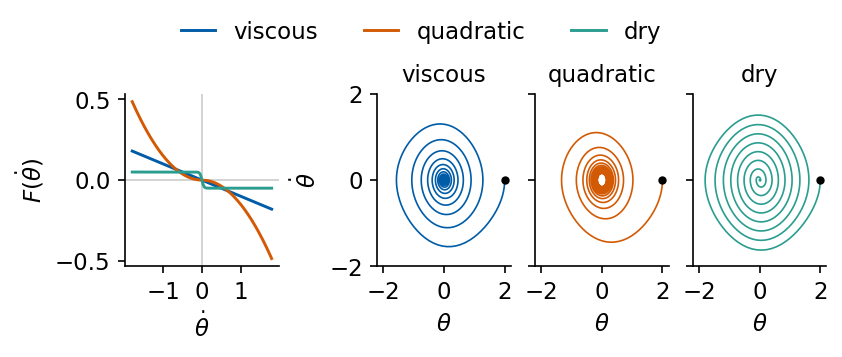

In [5]:
with mpl.rc_context(SLIDE_RC):
    fig = plt.figure(figsize=(5.5, 2.3), layout="constrained")
    gs = fig.add_gridspec(1, 4, width_ratios=[1.15, 1, 1, 1])
    ax = fig.add_subplot(gs[0])
    w = np.linspace(-1.8, 1.8, 801)
    for law in LAWS:
        ax.plot(w, FRICTION[law](w, COEF[law]), color=LAW_COLOR[law], label=law)
    ax.axhline(0, color="0.8", lw=0.8, zorder=0); ax.axvline(0, color="0.8", lw=0.8, zorder=0)
    ax.set_xlabel(r"$\dot\theta$"); ax.set_ylabel(r"$F(\dot\theta)$")
    fig.legend(*ax.get_legend_handles_labels(), loc="outside upper center", ncol=3, handlelength=1.5)
    for i, law in enumerate(LAWS):
        ax = fig.add_subplot(gs[i + 1])
        ax.plot(true[law][:, 0], true[law][:, 1], color=LAW_COLOR[law], lw=0.8)
        ax.plot(*np.asarray(S0_TRUE), "o", color="k", ms=3)
        ax.set_xlim(-2.2, 2.2); ax.set_ylim(-2.0, 2.0); ax.set_xticks([-2, 0, 2]); ax.set_yticks([-2, 0, 2])
        ax.set_xlabel(r"$\theta$"); ax.set_title(law)
        if i == 0: ax.set_ylabel(r"$\dot\theta$")
        else: ax.set_yticklabels([])
    save(fig, "fig_lab043_friction_laws"); plt.show()

### Energy loss per swing

Each friction law produces its own decay of the energy. Between two turning points, a half swing, the energy changes by $\Delta E=\int\dot\theta\,F(\dot\theta)\,dt$. For small amplitudes $A$ the motion inside one half swing is close to $\theta=A\cos t$, and the integral gives three different laws for the amplitude $A_n$ at the $n$-th turning point,
$$\text{viscous}\quad \ln A_{n+1}-\ln A_n=-\frac{\pi\gamma}{2},\qquad
\text{quadratic}\quad \frac1{A_{n+1}}-\frac1{A_n}=\frac{4c}{3},\qquad
\text{dry}\quad A_n-A_{n+1}=2\mu . \tag{6}$$
Viscous friction makes the amplitude decay exponentially, quadratic drag makes $1/A_n$ grow linearly, so that $A_n$ falls like $1/n$, and dry friction removes a fixed amount of amplitude per half swing until the pendulum stops. The turning points are found as the local extrema of $\theta(t)$ on the stored grid, refined by a parabola through the three neighbouring samples, and the energy at a turning point is $E_n=\omega_0^2(1-\cos A_n)$. We fit the three predicted straight lines to the half swings with $A_n<1$, where the small-amplitude formulas apply, and compare the slopes with the predictions.

In [6]:
def turning_points(t, th, min_amp=0.0):
    # times and amplitudes |theta| of the local extrema of theta(t), refined by a parabola through 3 samples
    t, th = np.asarray(t), np.asarray(th)
    k = np.nonzero(((th[1:-1] > th[:-2]) & (th[1:-1] >= th[2:])) | ((th[1:-1] < th[:-2]) & (th[1:-1] <= th[2:])))[0] + 1
    y0, y1, y2 = th[k - 1], th[k], th[k + 1]
    den = y0 - 2 * y1 + y2
    d = np.where(np.abs(den) > 1e-14, 0.5 * (y0 - y2) / np.where(den == 0, 1, den), 0.0)   # vertex offset in steps
    tp, amp = t[k] + d * (t[1] - t[0]), np.abs(y1 - 0.25 * (y0 - y2) * d)
    keep = amp > min_amp
    return tp[keep], amp[keep]

TRANSFORM = {"viscous": (np.log, r"$\ln A_n$", lambda p: -np.pi * p / 2),
             "quadratic": (lambda a: 1 / a, r"$1/A_n$", lambda p: 4 * p / 3),
             "dry": (lambda a: a, r"$A_n$", lambda p: -2 * p)}
decay = {}
for law in LAWS:
    tp, amp = turning_points(t_grid, true[law][:, 0], min_amp=0.02)
    n = np.arange(len(amp))
    g, _, pred = TRANSFORM[law]
    sel = amp < 1.0
    slope = np.polyfit(n[sel], g(amp[sel]), 1)[0]
    decay[law] = dict(t=tp, A=amp, slope=slope, pred=pred(COEF[law]))
    print(f"{law:9s} {len(amp):3d} half swings, slope of {TRANSFORM[law][1]:10s} for A_n < 1: "
          f"{slope:+.4f}   small-amplitude prediction {pred(COEF[law]):+.4f}")
    nums[f"decay_slope_{law}"] = float(slope); nums[f"decay_pred_{law}"] = float(pred(COEF[law]))

viscous    27 half swings, slope of $\ln A_n$  for A_n < 1: -0.1585   small-amplitude prediction -0.1571
quadratic  31 half swings, slope of $1/A_n$    for A_n < 1: +0.2013   small-amplitude prediction +0.2000
dry        16 half swings, slope of $A_n$      for A_n < 1: -0.1026   small-amplitude prediction -0.1000


The fitted slopes agree with the small-amplitude predictions to within 3 per cent, and the remaining difference comes from the anharmonicity of the swings with amplitudes close to one. We plot the energy $E(t)$ on a logarithmic scale (left) and the turning-point amplitudes $A_n$ (right). All three swings start with the same energy $E(0)=1-\cos2\approx1.42$. Under viscous friction $\ln E$ falls on a straight line. Quadratic drag removes energy fast while the swing is large and slowly once it is small, so the curve flattens. Dry friction removes the energy in equal steps of amplitude and brings the pendulum to rest after a finite number of half swings, after which the energy drops to zero within the smoothing width.

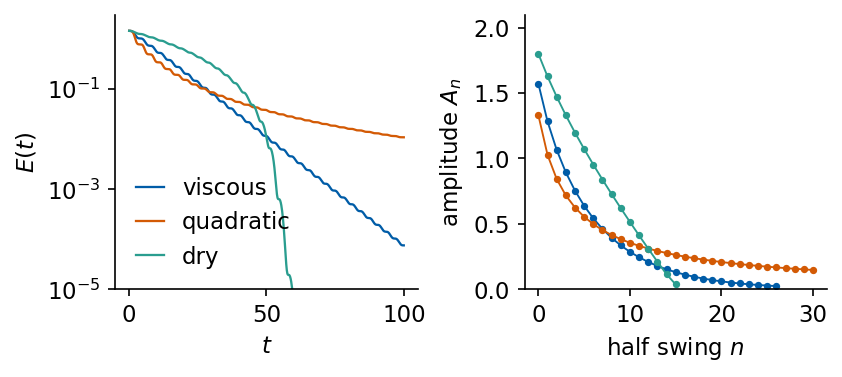

In [7]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 2, figsize=(5.5, 2.4), layout="constrained")
    for law in LAWS:
        axs[0].semilogy(t_grid, energy(true[law]), color=LAW_COLOR[law], lw=1.1, label=law)
        axs[1].plot(np.arange(len(decay[law]["A"])), decay[law]["A"], "o-", color=LAW_COLOR[law], ms=2.5, lw=0.9, label=law)
    axs[0].set_ylim(1e-5, 3); axs[0].set_xlabel("$t$"); axs[0].set_ylabel("$E(t)$")
    axs[0].legend(loc="lower left", handlelength=1.2)
    axs[1].set_xlabel("half swing $n$"); axs[1].set_ylabel("amplitude $A_n$"); axs[1].set_ylim(0, 2.1)
    save(fig, "fig_lab043_energy_decay"); plt.show()

<hr/>
## 2. One measured swing

The data are a single swing with quadratic air drag. A sensor records the angle $\theta$ and the angular velocity $\dot\theta$ every $\Delta t=0.1$ during the measured window $0\le t\le20$, about three periods. Each recorded value carries independent Gaussian noise of standard deviation $\sigma=0.02$,
$$\tilde\theta_k=\theta(t_k)+\sigma\xi_k,\qquad \tilde{\dot\theta}_k=\dot\theta(t_k)+\sigma\eta_k,\qquad t_k=k\,\Delta t,\quad k=0,\dots,200 . \tag{7}$$
The models learn from these 201 noisy states only. The law $F_{\rm quad}$ and its coefficient $c=0.15$ stay hidden. The noise-free trajectory up to $t=100$ is kept for testing the forecasts.

201 measured states, noise sigma = 0.02, rms deviation from the truth 0.0183
largest |thetadot| in the window 1.44, amplitude falls from 2 to 0.62


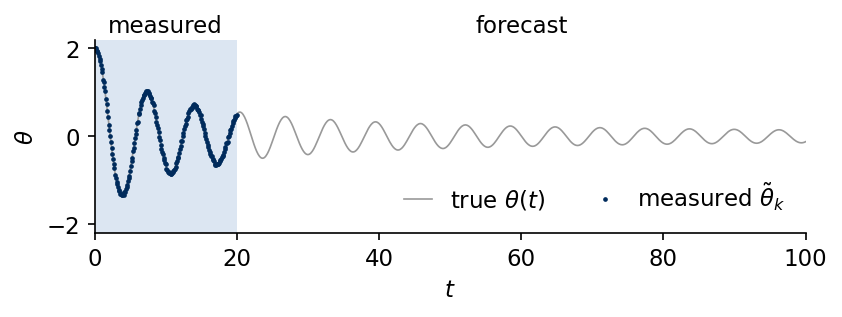

In [8]:
SIGMA = 0.02
rng = np.random.default_rng(1)
def measure(law, rng):
    # noisy theta and thetadot at t_k = 0, 0.1, ..., 20
    return true[law][:N_TRAIN + 1] + SIGMA * rng.normal(size=(N_TRAIN + 1, 2))

LAW = "quadratic"                       # hidden truth of the main experiment
data = measure(LAW, rng)
t_data = t_grid[:N_TRAIN + 1]
print(f"{len(data)} measured states, noise sigma = {SIGMA}, "
      f"rms deviation from the truth {np.sqrt(np.mean((data - true[LAW][:N_TRAIN + 1]) ** 2)):.4f}")
print(f"largest |thetadot| in the window {np.abs(true[LAW][:N_TRAIN + 1, 1]).max():.2f}, "
      f"amplitude falls from 2 to {decay[LAW]['A'][decay[LAW]['t'] < T_TRAIN][-1]:.2f}")
nums["n_data"] = len(data); nums["sigma"] = SIGMA
nums["max_thetadot_train"] = float(np.abs(true[LAW][:N_TRAIN + 1, 1]).max())

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.0), layout="constrained")
    ax.axvspan(0, T_TRAIN, color="#DCE6F2", lw=0, zorder=0)
    ax.text(T_TRAIN / 2, 2.25, "measured", ha="center", va="bottom")
    ax.text((T_TRAIN + T_END) / 2, 2.25, "forecast", ha="center", va="bottom")
    ax.plot(t_grid, true[LAW][:, 0], color="0.6", lw=0.8, label=r"true $\theta(t)$")
    ax.plot(t_data, data[:, 0], ".", color=UJNavy, ms=2.5, label=r"measured $\tilde\theta_k$")
    ax.set_xlim(0, T_END); ax.set_ylim(-2.2, 2.2); ax.set_xlabel("$t$"); ax.set_ylabel(r"$\theta$")
    ax.legend(loc="lower right", ncol=2, handlelength=1.2)
    save(fig, "fig_lab043_data"); plt.show()

<hr/>
## 3. Three models

All three models are ODEs for the state $\mathbf s=(\theta,\dot\theta)$, integrated by RK4 from a measured initial state.

The gravity-only model drops the friction, $\ddot\theta=-\omega_0^2\sin\theta$. It has no free parameter and conserves the energy.

The neural ODE replaces the whole vector field by a network, $\dot{\mathbf s}=\mathbf N_\phi(\mathbf s)$, with two inputs and two outputs. It knows neither gravity nor the kinematic relation between $\theta$ and $\dot\theta$ and must learn both from the data.

The hybrid model keeps everything we trust and learns only the friction,
$$\dot\theta=\dot\theta,\qquad \ddot\theta=-\omega_0^2\sin\theta+U_\theta(\theta,\dot\theta). \tag{8}$$
The network $U_\theta$ receives both components of the state, so that it can in principle also represent a force that depends on the angle. The subscript $\theta$ of $U_\theta$ denotes the network weights, following the notation of Rackauckas *et al.*, and is unrelated to the angle.

Both networks are multilayer perceptrons with two hidden layers of 32 tanh units,
$$\mathbf h_1=\tanh(W_1\mathbf s+\mathbf b_1),\qquad \mathbf h_2=\tanh(W_2\mathbf h_1+\mathbf b_2),\qquad \text{output}=W_3\mathbf h_2+\mathbf b_3, \tag{9}$$
with one output for $U_\theta$ and two for $\mathbf N_\phi$. The weights start from a normal distribution of variance $1/n_{\rm in}$ and the biases from zero. The last layer of $U_\theta$ is scaled by $0.1$ at initialisation, so that the hybrid model starts close to the gravity-only model. The two networks enter the vector field that the solver integrates in different ways.

In [9]:
def init_mlp(key, sizes, last_scale=1.0):
    # list of (W, b) for the layer widths `sizes`; W ~ N(0, 1/n_in), b = 0, last layer scaled by last_scale
    params = []
    for i, (n_in, n_out) in enumerate(zip(sizes[:-1], sizes[1:])):
        key, k = jax.random.split(key)
        W = jax.random.normal(k, (n_in, n_out)) / np.sqrt(n_in)
        params.append((W * (last_scale if i == len(sizes) - 2 else 1.0), jnp.zeros(n_out)))
    return params

def mlp(params, x):
    # tanh hidden layers, linear output layer
    for W, b in params[:-1]:
        x = jnp.tanh(x @ W + b)
    W, b = params[-1]
    return x @ W + b

def n_params(params):
    return int(sum(p.size for p in jax.tree.leaves(params)))

SIZES_U, SIZES_N = [2, 32, 32, 1], [2, 32, 32, 2]

def f_gravity(s, t):
    return jnp.array([s[1], -W0SQ * jnp.sin(s[0])])

def f_neural(params):
    return lambda s, t: mlp(params, s)

def f_hybrid(params):
    return lambda s, t: jnp.array([s[1], -W0SQ * jnp.sin(s[0]) + mlp(params, s)[0]])

print("parameters: U_theta", n_params(init_mlp(jax.random.PRNGKey(0), SIZES_U)),
      "| N_phi", n_params(init_mlp(jax.random.PRNGKey(0), SIZES_N)))
nums["n_params_U"] = n_params(init_mlp(jax.random.PRNGKey(0), SIZES_U))
nums["n_params_N"] = n_params(init_mlp(jax.random.PRNGKey(0), SIZES_N))

parameters: U_theta 1185 | N_phi 1218


The drawing, made with the helper functions `draw_layers`, `box` and `arrow`, shows each fully connected network as columns of nodes joined by edges, with dots marking the columns that hold more units than drawn, and the other operations as labelled rectangles joined by arrows. The upper panel shows the neural ODE, where the network output is the whole vector field. The lower panel shows the hybrid model, where the network adds the friction $U_\theta$ to the known gravitational term, and the sum enters the vector field $\mathbf f=(\dot\theta,\ddot\theta)$ that RK4 integrates from $t$ to $t+h$. The new state is fed back as the next input.

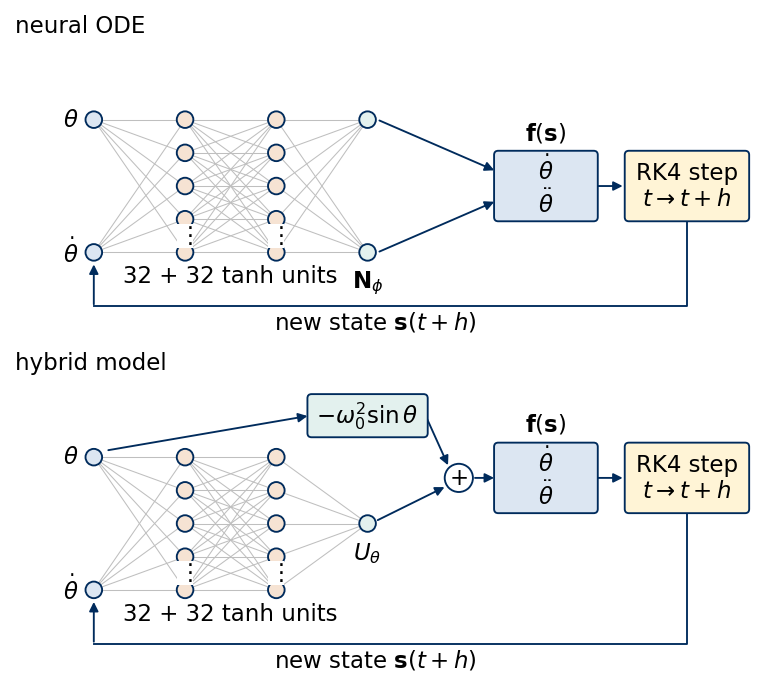

In [10]:
def draw_layers(ax, sizes, xs, ys_span=1.6, node_r=0.1, colors=None, y0=0.0, edge_color="0.75"):
    """Nodes-and-edges drawing of a fully connected network.

    sizes[i] nodes are placed in a vertical column at x = xs[i], centred at height y0; every node of a
    column is joined to every node of the next column (a dense layer).
    Returns the node coordinates, one list of (x, y) per column, for arrows and labels.
    """
    cols = []
    for n, x in zip(sizes, xs):
        ys = y0 + (np.linspace(ys_span / 2, -ys_span / 2, n) if n > 1 else np.array([0.0]))
        cols.append([(x, y) for y in ys])
    for a, b in zip(cols[:-1], cols[1:]):            # edges first, so that the nodes are drawn on top
        for (xa, ya) in a:
            for (xb, yb) in b:
                ax.plot([xa, xb], [ya, yb], color=edge_color, lw=0.5, zorder=1)
    for i, col in enumerate(cols):                    # nodes as circles, one fill colour per column
        for (x, y) in col:
            ax.add_patch(Circle((x, y), node_r, fc=(colors[i] if colors else "#DCE6F2"), ec=UJNavy, lw=0.9, zorder=3))
    return cols

def box(ax, x, y, w, h, text, fc="#F6E3D3"):
    # rounded rectangle centred at (x, y) with a label
    ax.add_patch(FancyBboxPatch((x - w / 2, y - h / 2), w, h, boxstyle="round,pad=0.05", fc=fc, ec=UJNavy, lw=0.9, zorder=3))
    ax.text(x, y, text, ha="center", va="center", zorder=4)

def arrow(ax, p, q, rad=0.0):
    ax.add_patch(FancyArrowPatch(p, q, arrowstyle="-|>", mutation_scale=9, color=UJNavy, lw=0.9,
                                 connectionstyle=f"arc3,rad={rad}", zorder=2, shrinkA=1, shrinkB=1))

def dots(ax, col):
    # vertical dots between the last two drawn nodes of a wide column
    ax.text(col[0][0], 0.5 * (col[-2][1] + col[-1][1]), r"$\vdots$", ha="center", va="center", zorder=4,
            bbox=dict(fc="white", ec="none", pad=0.3))

NODE_COLORS = ["#DCE6F2", "#F6E3D3", "#F6E3D3", "#E3F1EE"]
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(2, 1, figsize=(5.5, 4.5), layout="constrained")
    for ax, hybrid in zip(axs, (False, True)):
        n_out = 1 if hybrid else 2
        cols = draw_layers(ax, [2, 5, 5, n_out], xs=[0.6, 1.7, 2.8, 3.9], colors=NODE_COLORS)
        dots(ax, cols[1]); dots(ax, cols[2])
        ax.text(cols[0][0][0] - 0.18, cols[0][0][1], r"$\theta$", ha="right", va="center")
        ax.text(cols[0][1][0] - 0.18, cols[0][1][1], r"$\dot\theta$", ha="right", va="center")
        ax.text(2.25, -0.95, "32 + 32 tanh units", ha="center", va="top")
        yb = 0.55 if hybrid else 0.0          # height of the vector-field box and the solver box
        if hybrid:
            ax.text(3.9, -0.2, r"$U_\theta$", ha="center", va="top")
            box(ax, 3.9, 1.3, 1.35, 0.42, r"$-\omega_0^2\sin\theta$", fc="#E3F1EE")      # known physics
            arrow(ax, (0.75, 0.88), (3.2, 1.3))
            ax.add_patch(Circle((5.0, 0.55), 0.17, fc="white", ec=UJNavy, lw=0.9, zorder=3))
            ax.text(5.0, 0.55, "+", ha="center", va="center", zorder=4)
            arrow(ax, (4.0, 0.03), (4.85, 0.45)); arrow(ax, (4.6, 1.3), (4.88, 0.68))
            box(ax, 6.05, yb, 1.15, 0.75, r"$\dot\theta$" + "\n" + r"$\ddot\theta$", fc="#DCE6F2")
            arrow(ax, (5.17, 0.55), (5.45, 0.55))
            ax.text(6.05, yb + 0.5, r"$\mathbf{f}(\mathbf{s})$", ha="center", va="bottom")
            ax.set_title("hybrid model", loc="left")
        else:
            ax.text(3.9, -1.0, r"$\mathbf{N}_\phi$", ha="center", va="top")
            box(ax, 6.05, yb, 1.15, 0.75, r"$\dot\theta$" + "\n" + r"$\ddot\theta$", fc="#DCE6F2")
            for (x, y) in cols[3]:                    # both network outputs enter the vector field
                arrow(ax, (x + 0.12, y), (5.45, 0.18 * np.sign(y)))
            ax.text(6.05, yb + 0.5, r"$\mathbf{f}(\mathbf{s})$", ha="center", va="bottom")
            ax.set_title("neural ODE", loc="left")
        box(ax, 7.75, yb, 1.4, 0.75, "RK4 step\n" + r"$t\to t+h$", fc="#FFF4D6")
        arrow(ax, (6.65, yb), (7.0, yb))
        # feedback of the new state s(t+h) to the input layer: down, left, up
        y_low = -1.45
        ax.plot([7.75, 7.75, 0.6], [yb - 0.42, y_low, y_low], color=UJNavy, lw=0.9, zorder=2)
        arrow(ax, (0.6, y_low), (0.6, -0.92))
        ax.text(4.0, y_low - 0.05, r"new state $\mathbf{s}(t+h)$", ha="center", va="top")
        ax.set_xlim(-0.35, 8.6); ax.set_ylim(-1.85, 1.7); ax.set_aspect("equal"); ax.axis("off")
    save(fig, "fig_lab043_architectures"); plt.show()

<hr/>
## 4. Training through the solver

A loss on the trajectory requires integrating the model ODE and differentiating the result with respect to the network weights. Integrating from $t=0$ over the whole window at once is possible, but a small change of the vector field shifts the phase of all later swings, which makes such a loss hard to minimise from a poor initial guess. We therefore use short segments, an approach known as multiple shooting. Each of the measured states $\tilde{\mathbf s}_k$ with $k=0,\dots,170$ starts a segment, which the model integrates over $H=30$ steps of $\Delta t$, about half a period. The loss is the mean squared deviation of the integrated states $\hat{\mathbf s}$ from the measured ones,
$$\mathcal L=\frac{1}{2\,n_{\rm seg}(H+1)}\sum_{k=0}^{n_{\rm seg}-1}\sum_{j=0}^{H}\big\|\hat{\mathbf s}(t_{k+j};\tilde{\mathbf s}_k)-\tilde{\mathbf s}_{k+j}\big\|^2,\qquad n_{\rm seg}=171, \tag{10}$$
where $\hat{\mathbf s}(t;\tilde{\mathbf s}_k)$ is the model solution started from $\tilde{\mathbf s}_k$ at $t_k$. The noise alone contributes $\sigma^2=4\times10^{-4}$ per component, the smallest value the loss can reach on average. All segments are integrated in parallel with `jax.vmap`.

Before training we check the gradient of the loss. `jax.grad` differentiates through the RK4 steps. An independent value comes from the adaptive `Tsit5` solver of `diffrax` [Ch. Tsitouras, Comput. Math. Appl. **62**, 770 (2011), [doi:10.1016/j.camwa.2011.06.002](https://doi.org/10.1016/j.camwa.2011.06.002)] with tolerances $10^{-12}$, which integrates all segments as one batched state. For a random unit direction $\mathbf v$ in weight space we compare the directional derivative $\nabla\mathcal L\cdot\mathbf v$ from `jax.grad` with the central difference $[\mathcal L_{\rm Tsit5}(\mathbf w+\epsilon\mathbf v)-\mathcal L_{\rm Tsit5}(\mathbf w-\epsilon\mathbf v)]/(2\epsilon)$ with $\epsilon=10^{-4}$, where $\mathbf w$ denotes all weights of $U_\theta$. The difference between them is dominated by the discretisation error of RK4, so it should shrink by about $4^4=256$ when the RK4 step is divided by four.

In [11]:
H_SEG = 30
starts = np.arange(0, N_TRAIN - H_SEG + 1)                  # k = 0, ..., 170
idx = starts[:, None] + np.arange(H_SEG + 1)[None, :]

def segment_loss(f_maker, data, sub=1, solver="rk4"):
    # multiple-shooting loss: every measured state starts a segment of H_SEG steps
    S0, target = jnp.asarray(data[starts]), jnp.asarray(data[idx])
    ts = jnp.arange(H_SEG + 1) * DT
    def loss(params):
        f = f_maker(params)
        if solver == "rk4":
            traj = jax.vmap(lambda s: rk4_solve(f, s, 0.0, H_SEG, DT, sub=sub))(S0)
        else:   # adaptive Tsit5 of diffrax; all segments form one batched state of shape (n_seg, 2)
            ys = diffrax_solve(lambda S, t: jax.vmap(lambda s: f(s, t))(S), S0, ts, solver=diffrax.Tsit5(), tol=1e-12)
            traj = jnp.swapaxes(ys, 0, 1)
        return jnp.mean((traj - target) ** 2)
    return loss

# directional derivative of the loss along a random unit direction v of the weights
p_test = init_mlp(jax.random.PRNGKey(3), SIZES_U, last_scale=1.0)
leaves, treedef = jax.tree.flatten(p_test)
v = [jax.random.normal(jax.random.PRNGKey(10 + i), x.shape) for i, x in enumerate(leaves)]
v_norm = np.sqrt(sum(float(jnp.sum(x ** 2)) for x in v))
v = jax.tree.unflatten(treedef, [x / v_norm for x in v])
shift = lambda p, a: jax.tree.map(lambda x, y: x + a * y, p, v)
L_tsit = jax.jit(segment_loss(f_hybrid, data, solver="diffrax"))
h_fd = 1e-4
d_ref = (float(L_tsit(shift(p_test, h_fd))) - float(L_tsit(shift(p_test, -h_fd)))) / (2 * h_fd)
print(f"Tsit5 loss {float(L_tsit(p_test)):.6e}, central difference of the Tsit5 loss along v: {d_ref:.8e}")
for sub in (1, 4):
    g = jax.grad(segment_loss(f_hybrid, data, sub=sub))(p_test)
    d_rk4 = float(sum(jnp.sum(a * b) for a, b in zip(jax.tree.leaves(g), jax.tree.leaves(v))))
    rel = abs(d_rk4 - d_ref) / abs(d_ref)
    print(f"RK4 step {DT / sub:.3f}: jax.grad . v = {d_rk4:.8e}, relative difference {rel:.1e}")
    nums[f"grad_rel_diff_sub{sub}"] = rel

Tsit5 loss 1.789849e-02, central difference of the Tsit5 loss along v: -7.89445890e-03
RK4 step 0.100: jax.grad . v = -7.89447893e-03, relative difference 2.5e-06
RK4 step 0.025: jax.grad . v = -7.89445902e-03, relative difference 1.4e-08


The relative difference of the two derivatives is $2.5\times10^{-6}$ at the sampling step and $1.4\times10^{-8}$ at a four times smaller step, a reduction by a factor of about 180, close to the factor 256 expected from a fourth-order method. Training therefore uses RK4 with step $\Delta t$.

The optimiser is Adam [D. P. Kingma, J. Ba, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)] with a learning rate that starts at $3\times10^{-3}$ and decays along a cosine to $1.5\times10^{-4}$ over 3000 full-batch updates. Each update is one jit-compiled call of `jax.value_and_grad` followed by `optax`.

In [12]:
N_STEPS, LR0 = 3000, 3e-3

def train(f_maker, params, data, n_steps=N_STEPS, lr=LR0):
    loss = segment_loss(f_maker, data)
    tx = optax.adam(optax.cosine_decay_schedule(lr, n_steps, alpha=0.05))
    opt_state = tx.init(params)
    @jax.jit
    def update(params, opt_state):
        l, g = jax.value_and_grad(loss)(params)
        u, opt_state = tx.update(g, opt_state, params)
        return optax.apply_updates(params, u), opt_state, l
    hist = np.empty(n_steps)
    for i in range(n_steps):
        params, opt_state, l = update(params, opt_state)
        hist[i] = l
    return params, hist, float(loss(params))

fits = {}
for name, f_maker, sizes, scale in (("hybrid", f_hybrid, SIZES_U, 0.1), ("neural ODE", f_neural, SIZES_N, 1.0)):
    t0 = time.time()
    p, hist, l_end = train(f_maker, init_mlp(jax.random.PRNGKey(0), sizes, last_scale=scale), data)
    fits[name] = dict(params=p, hist=hist, loss=l_end, time=time.time() - t0)
    print(f"{name:10s} loss {hist[0]:.2e} -> {l_end:.2e}   ({fits[name]['time']:.0f} s)")
    nums[f"loss_{name}"] = l_end; nums[f"train_time_{name}"] = fits[name]["time"]
loss_gravity = float(segment_loss(lambda p: f_gravity, data)(None))
print(f"gravity only loss {loss_gravity:.2e}   noise floor sigma^2 = {SIGMA ** 2:.1e}")
nums["loss_gravity"] = loss_gravity

hybrid     loss 1.86e-02 -> 5.87e-04   (74 s)
neural ODE loss 1.86e+00 -> 6.57e-04   (100 s)
gravity only loss 1.38e-02   noise floor sigma^2 = 4.0e-04


The hybrid model ends at $\mathcal L=5.9\times10^{-4}$ and the neural ODE at $6.6\times10^{-4}$, both about 1.5 times the noise floor $\sigma^2$, while gravity alone gives $1.4\times10^{-2}$. The excess over $\sigma^2$ comes from the noise of the measured initial state of each segment, which the model carries along the segment. The learning curves show that the hybrid model starts close to the gravity-only loss, since its friction term is small at initialisation, and reaches its final level within about 200 updates. The neural ODE starts from a random vector field with a loss two orders of magnitude higher and needs most of the budget.

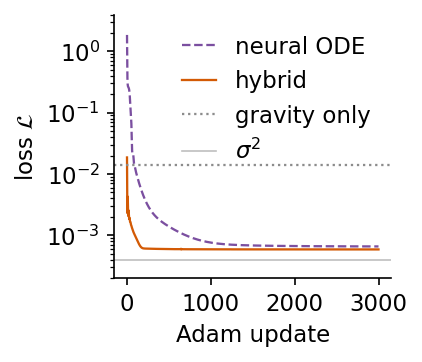

In [13]:
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(2.7, 2.3), layout="constrained")
    for name in ("neural ODE", "hybrid"):
        ax.semilogy(np.arange(1, N_STEPS + 1), fits[name]["hist"], **STYLE[name], lw=1.1, label=name)
    ax.axhline(loss_gravity, **STYLE["gravity only"], lw=1.1, label="gravity only")
    ax.axhline(SIGMA ** 2, color="0.75", lw=0.8, label=r"$\sigma^2$")
    ax.set_ylim(2e-4, 4); ax.set_xlabel("Adam update"); ax.set_ylabel(r"loss $\mathcal{L}$")
    ax.legend(loc="upper right", handlelength=1.5)
    save(fig, "fig_lab043_training"); plt.show()

<hr/>
## 5. Learned friction and its formula

The trained network $U_\theta$ is a function of two variables, but the measured states cover only a thin spiral in the $(\theta,\dot\theta)$ plane, and the network is constrained by the data only there. We therefore evaluate $U_\theta$ at the 201 measured states and plot it against their angular velocity $\tilde{\dot\theta}_k$, together with the hidden law $F_{\rm quad}(\dot\theta)=-0.15\,\dot\theta|\dot\theta|$. If the network had learned a force that depends on the angle as well, points with the same $\dot\theta$ but different $\theta$ would scatter vertically. The points follow the parabola closely, and the root-mean-square deviation of $U_\theta$ from the true law over the measured states is 7.6 per cent of the root-mean-square friction.

on the measured states: rms(U_theta - F) / rms(F) = 0.076


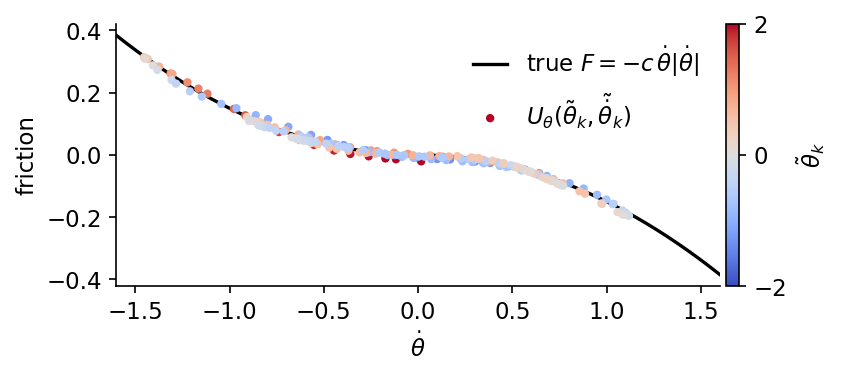

In [14]:
U_fn = jax.jit(jax.vmap(lambda s: mlp(fits["hybrid"]["params"], s)[0]))
W_MAX = nums["max_thetadot_train"]
U_data = np.asarray(U_fn(jnp.asarray(data)))
F_data = np.asarray(FRICTION[LAW](data[:, 1], COEF[LAW]))
rel_U = np.sqrt(np.mean((U_data - F_data) ** 2) / np.mean(F_data ** 2))
print(f"on the measured states: rms(U_theta - F) / rms(F) = {rel_U:.3f}")
nums["U_rel_error_data"] = float(rel_U)

w_plot = np.linspace(-1.6, 1.6, 401)
with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.4), layout="constrained")
    ax.plot(w_plot, FRICTION[LAW](w_plot, COEF[LAW]), color="k", lw=1.6, label=r"true $F=-c\,\dot\theta|\dot\theta|$")
    sc = ax.scatter(data[:, 1], U_data, c=data[:, 0], cmap="coolwarm", vmin=-2, vmax=2, s=9, zorder=3,
                    label=r"$U_\theta(\tilde\theta_k,\tilde{\dot\theta}_k)$")
    fig.colorbar(sc, ax=ax, label=r"$\tilde\theta_k$", ticks=[-2, 0, 2], pad=0.01)
    ax.set_xlabel(r"$\dot\theta$"); ax.set_ylabel("friction"); ax.set_xlim(-1.6, 1.6)
    ax.legend(loc="upper right", handlelength=1.5)
    save(fig, "fig_lab043_learned_friction"); plt.show()

### Sparse regression

To turn $U_\theta$ into a formula we expand its values at the measured states in a library of $m=8$ candidate functions $\Theta_j(\theta,\dot\theta)$,
$$U_\theta(\tilde{\mathbf s}_k)\approx\sum_{j=1}^{m}\xi_j\,\Theta_j(\tilde{\mathbf s}_k),\qquad
\Theta=\big\{1,\ \sin\theta,\ \theta^2,\ \theta\dot\theta,\ \dot\theta,\ \dot\theta|\dot\theta|,\ \tanh(\dot\theta/\varepsilon),\ \dot\theta^3\big\}. \tag{11}$$
The library contains the three friction laws, a cubic velocity term and three functions that involve the angle, so the regression has to choose. Most coefficients $\xi_j$ should vanish, and sequentially thresholded least squares (STLSQ) enforces this sparsity [Brunton, Proctor and Kutz (2016)]. Each library column is divided by its root mean square over the data, so that a coefficient $\hat\xi_j$ of the scaled problem measures the typical size of term $j$ in units of the friction. STLSQ first solves the regression with all columns, then sets every $\hat\xi_j$ with $|\hat\xi_j|<\lambda$ to zero and solves the regression again on the remaining columns. These two operations are repeated until the set of active terms no longer changes.

The four velocity functions are strongly correlated on the data, since all of them are odd in $\dot\theta$ and grow with $|\dot\theta|$. Ordinary least squares then tends to return large coefficients of opposite sign that cancel each other, and no single coefficient falls below the threshold. Each solve inside STLSQ therefore minimises the ridge-regularised squared error
$$\sum_k\Big(U_\theta(\tilde{\mathbf s}_k)-\sum_j\hat\xi_j\hat\Theta_{kj}\Big)^2+\alpha\,n\,\|\hat{\boldsymbol\xi}\|^2,\qquad \alpha=0.01, \tag{12}$$
with $n=201$ data points and the scaled columns $\hat\Theta_{kj}$. The penalty suppresses such cancelling combinations. After the active set has converged, its coefficients are refitted by plain least squares, so that the penalty does not shrink the final values. The threshold is $\lambda=0.35\,{\rm rms}(U_\theta)$, which drops a term when its typical contribution is below 35 per cent of the typical learned friction.

In [15]:
LIB_NAMES = ["1", r"\sin\theta", r"\theta^2", r"\theta\dot\theta", r"\dot\theta",
             r"\dot\theta|\dot\theta|", r"\tanh(\dot\theta/\varepsilon)", r"\dot\theta^3"]
def library(S, xp=np):
    # columns Theta_j(theta, thetadot) for states S of shape (n, 2); xp = np or jnp
    th, w = S[:, 0], S[:, 1]
    return xp.stack([xp.ones_like(th), xp.sin(th), th ** 2, th * w, w, w * xp.abs(w), xp.tanh(w / EPS), w ** 3], 1)
LAW_TERM = {"viscous": r"\dot\theta", "quadratic": r"\dot\theta|\dot\theta|", "dry": r"\tanh(\dot\theta/\varepsilon)"}

ALPHA, LAM_REL = 0.01, 0.35
def stlsq(Theta, y, lam, alpha=ALPHA, max_iter=20):
    # sequentially thresholded ridge regression on RMS-scaled columns, final plain least-squares refit;
    # returns the coefficients of the unscaled columns
    n = len(y)
    scale = np.sqrt(np.mean(Theta ** 2, 0))
    A = Theta / scale
    ridge = lambda M: np.linalg.solve(M.T @ M + alpha * n * np.eye(M.shape[1]), M.T @ y)
    xi = ridge(A)
    active = np.ones(len(xi), bool)
    for _ in range(max_iter):
        new = active & (np.abs(xi) >= lam)
        xi = np.zeros_like(xi)
        if new.any():
            xi[new] = ridge(A[:, new])
        if np.array_equal(new, active):
            break
        active = new
    xi = np.zeros_like(xi)
    if active.any():
        xi[active] = np.linalg.lstsq(A[:, active], y, rcond=None)[0]
    return xi / scale

def sparse_fit(S, U):
    return stlsq(library(S), U, LAM_REL * np.sqrt(np.mean(U ** 2)))

def formula(xi, names=LIB_NAMES):
    return " ".join(f"{v:+.4f} {n}" for v, n in zip(xi, names) if v != 0) or "0"

Theta_data = library(data)
xi_ls = np.linalg.lstsq(Theta_data, U_data, rcond=None)[0]
xi_plain = stlsq(Theta_data, U_data, LAM_REL * np.sqrt(np.mean(U_data ** 2)), alpha=0.0)
xi = sparse_fit(data, U_data)
print("least squares, all columns:", formula(xi_ls))
print("STLSQ without ridge       :", formula(xi_plain))
print("STLSQ with ridge          :", formula(xi))
c_rec = -xi[LIB_NAMES.index(LAW_TERM[LAW])]
print(f"recovered c = {c_rec:.4f}, true c = {COEF[LAW]}, relative error {abs(c_rec - COEF[LAW]) / COEF[LAW]:.1%}")
nums["c_recovered"] = float(c_rec); nums["c_true"] = COEF[LAW]
nums["n_active_terms"] = int((xi != 0).sum())

least squares, all columns: -0.0020 1 -0.0009 \sin\theta -0.0011 \theta^2 -0.0013 \theta\dot\theta +0.0357 \dot\theta -0.2097 \dot\theta|\dot\theta| -0.0057 \tanh(\dot\theta/\varepsilon) +0.0272 \dot\theta^3
STLSQ without ridge       : -0.1497 \dot\theta|\dot\theta|
STLSQ with ridge          : -0.1497 \dot\theta|\dot\theta|
recovered c = 0.1497, true c = 0.15, relative error 0.2%


The least-squares fit with all columns spreads the learned friction over all eight terms, with coefficients of both signs. STLSQ removes all of them except the quadratic drag term, and the coefficient refitted on that single column is $c=0.1497$, within 0.2 per cent of the hidden value $0.15$. For this network STLSQ without the ridge penalty selects the same term.

The selected terms depend on the threshold. For each $\lambda/{\rm rms}(U_\theta)$ on a logarithmic grid we record the number of active terms and the relative residual ${\rm rms}(U_\theta-\Theta\boldsymbol\xi)/{\rm rms}(U_\theta)$. Small thresholds keep many terms, yet the residual stays at about 0.07 all the way from eight terms down to one, so the additional terms describe only small details of the network. The single quadratic term survives for $0.25\le\lambda/{\rm rms}(U_\theta)\le0.45$, and above this window every term is removed and the residual jumps to one. The window is less than a factor of two wide, because the ridge solve with all columns shares the friction among the correlated velocity terms, so that no single coefficient is much larger than the others at the first step. The value $\lambda=0.35\,{\rm rms}(U_\theta)$ lies in its middle.

a single active term for lambda / rms(U) between 0.251 and 0.447, relative residual there 0.076


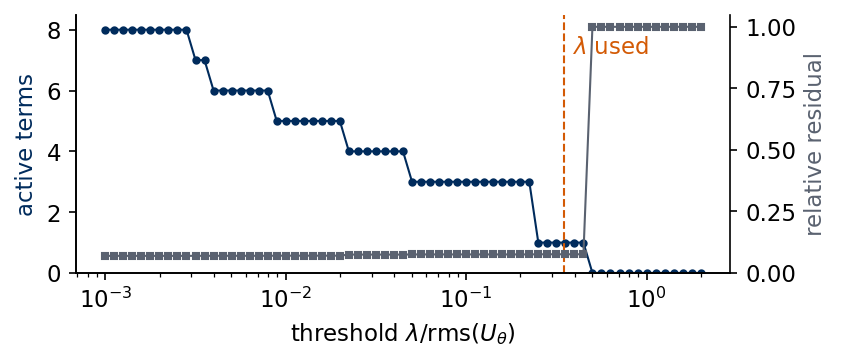

In [16]:
lams = np.logspace(-3, 0.3, 67)
rmsU = np.sqrt(np.mean(U_data ** 2))
n_act, resid = [], []
for lr_ in lams:
    x_ = stlsq(Theta_data, U_data, lr_ * rmsU)
    n_act.append(int((x_ != 0).sum()))
    resid.append(np.sqrt(np.mean((U_data - Theta_data @ x_) ** 2)) / rmsU)
n_act, resid = np.array(n_act), np.array(resid)
one = lams[n_act == 1]
print(f"a single active term for lambda / rms(U) between {one.min():.3f} and {one.max():.3f}, "
      f"relative residual there {resid[n_act == 1].min():.3f}")
nums["lam_single_min"], nums["lam_single_max"] = float(one.min()), float(one.max())
nums["resid_single"] = float(resid[n_act == 1].min())

with mpl.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(5.5, 2.3), layout="constrained")
    ax.semilogx(lams, n_act, "o-", color=UJNavy, ms=3, lw=1.0)
    ax.axvline(LAM_REL, color=DSOrange, lw=1.0, ls="--")
    ax.text(LAM_REL * 1.1, 7.8, r"$\lambda$ used", color=DSOrange, va="top")
    ax.set_xlabel(r"threshold $\lambda/\mathrm{rms}(U_\theta)$"); ax.set_ylabel("active terms", color=UJNavy)
    ax.set_ylim(0, 8.5)
    ax2 = ax.twinx(); ax2.spines["right"].set_visible(True)
    ax2.semilogx(lams, resid, "s-", color=UJGray, ms=2.5, lw=1.0)
    ax2.set_ylabel("relative residual", color=UJGray); ax2.set_ylim(0, 1.05)
    save(fig, "fig_lab043_threshold_scan"); plt.show()

### Sparse regression on raw derivatives

The original SINDy procedure works without a network. It estimates the derivative $\ddot\theta$ directly from the data by finite differences and regresses it on a library. For our data the central difference $(\tilde{\dot\theta}_{k+1}-\tilde{\dot\theta}_{k-1})/(2\Delta t)$ amplifies the measurement noise to a standard deviation $\sigma/(\sqrt2\,\Delta t)\approx0.14$, comparable with the friction itself. We run the same STLSQ with the same library and threshold on the target $\ddot\theta+\omega_0^2\sin\tilde\theta$, the part of the acceleration that gravity leaves unexplained, so that both regressions estimate the same function.

In [17]:
acc_fd = (data[2:, 1] - data[:-2, 1]) / (2 * DT)                  # central difference, k = 1..199
target_fd = acc_fd + W0SQ * np.sin(data[1:-1, 0])
xi_fd = sparse_fit(data[1:-1], target_fd)
print(f"noise of the finite-difference acceleration {SIGMA / (np.sqrt(2) * DT):.3f}, "
      f"rms of the true friction {np.sqrt(np.mean(F_data ** 2)):.3f}")
print("STLSQ on finite differences:", formula(xi_fd))
nums["c_fd"] = float(-xi_fd[LIB_NAMES.index(LAW_TERM[LAW])])
col = library(data[1:-1])[:, [LIB_NAMES.index(LAW_TERM[LAW])]]
c_fd_single = -np.linalg.lstsq(col, target_fd, rcond=None)[0][0]
print(f"least squares on the single true column: c = {c_fd_single:.3f} (true {COEF[LAW]})")
nums["c_fd_single"] = float(c_fd_single)

noise of the finite-difference acceleration 0.141, rms of the true friction 0.100
STLSQ on finite differences: 0
least squares on the single true column: c = 0.148 (true 0.15)


With the same threshold as for the network output, the regression on raw derivatives returns no term at all. Its target is dominated by the amplified noise, whose standard deviation 0.14 exceeds the root-mean-square friction 0.10, so every coefficient is small compared with ${\rm rms}$ of the target. The noise is unbiased, however. When the true column $\dot\theta|\dot\theta|$ is the only one offered, its least-squares coefficient is $c=0.148$, close to the true $0.15$, so the raw derivatives carry the information about the coefficient but are too noisy to select the term. The hybrid model avoids differentiating the data. The solver integrates the model, and the comparison of whole segments with the measured states averages the noise, so the network output is a far less noisy target for the sparse regression.
<hr/>
## 6. Forecast far beyond the measured window

We integrate four models from the first measured state $\tilde{\mathbf s}_0$ up to $t=100$, five times longer than the measured window. Besides the gravity-only model, the neural ODE and the hybrid model, the fourth model is the recovered equation
$$\ddot\theta=-\omega_0^2\sin\theta+\sum_j\xi_j\Theta_j(\theta,\dot\theta) \tag{13}$$
with the coefficients found by STLSQ. Two scores compare them with the true trajectory. The absolute angle error $|\Delta\theta(t)|=|\hat\theta(t)-\theta(t)|$ measures the deviation at each time, and the energy at the turning points $E_n=\omega_0^2(1-\cos A_n)$ shows whether a model loses energy at the right rate.

In [18]:
def f_from_xi(xi_):
    # recovered equation, the library evaluated with jax.numpy
    xi_ = jnp.asarray(xi_)
    return lambda s, t: jnp.array([s[1], -W0SQ * jnp.sin(s[0]) + library(s[None], jnp)[0] @ xi_])

s_start = jnp.asarray(data[0])
FIELDS = {"gravity only": f_gravity, "neural ODE": f_neural(fits["neural ODE"]["params"]),
          "hybrid": f_hybrid(fits["hybrid"]["params"]), "recovered": f_from_xi(xi)}
MODEL_NAMES = tuple(FIELDS)
fc = {name: np.asarray(rk4_solve(f, s_start, 0.0, N_END, DT)) for name, f in FIELDS.items()}
err = {name: np.abs(fc[name][:, 0] - true[LAW][:, 0]) for name in MODEL_NAMES}
test = t_grid > T_TRAIN
print(f"{'model':13s} {'rms dtheta, 0<t<20':>20s} {'rms dtheta, 20<t<100':>22s} {'E(100)':>10s}")
for name in MODEL_NAMES:
    r_tr, r_te = np.sqrt(np.mean(err[name][~test] ** 2)), np.sqrt(np.mean(err[name][test] ** 2))
    print(f"{name:13s} {r_tr:20.4f} {r_te:22.4f} {energy(fc[name][-1]):10.2e}")
    nums[f"rms_train_{name}"], nums[f"rms_test_{name}"] = float(r_tr), float(r_te)
    nums[f"E100_{name}"] = float(energy(fc[name][-1]))
print(f"{'truth':13s} {'':20s} {'':22s} {energy(true[LAW][-1]):10.2e}")
nums["E100_truth"] = float(energy(true[LAW][-1]))

model           rms dtheta, 0<t<20   rms dtheta, 20<t<100     E(100)
gravity only                1.3232                 1.4794   1.42e+00
neural ODE                  0.0164                 0.1765   6.23e-02
hybrid                      0.0108                 0.0475   2.27e-02
recovered                   0.0174                 0.0057   1.07e-02
truth                                                       1.07e-02


We tabulate the root-mean-square angle error inside and beyond the measured window and the energy at $t=100$, and we plot the trajectories (upper panel), the angle error on a logarithmic scale (middle panel) and the energy at the turning points (lower panel). Gravity alone keeps the initial amplitude, and its error reaches the size of the swing within the measured window. The neural ODE follows the data inside the window with an error of 0.016. Beyond it the swing enters the small-amplitude part of the phase plane that the measured swing never visited, where the learned vector field is unconstrained. Its energy at the turning points levels off near $0.06$, and its error grows to 0.18 for $20<t\le100$. The hybrid model extrapolates better, with an error of 0.048, since gravity is built in and only the friction has to be extrapolated, but it also loses energy too slowly at small amplitudes. The recovered equation has the functional form of the true friction everywhere. Inside the window its error of 0.017 is slightly larger than that of the hybrid model, which also fits part of the noise, while beyond the window its error of 0.006 is the smallest, and its energy at $t=100$ agrees with the truth to the three digits printed.

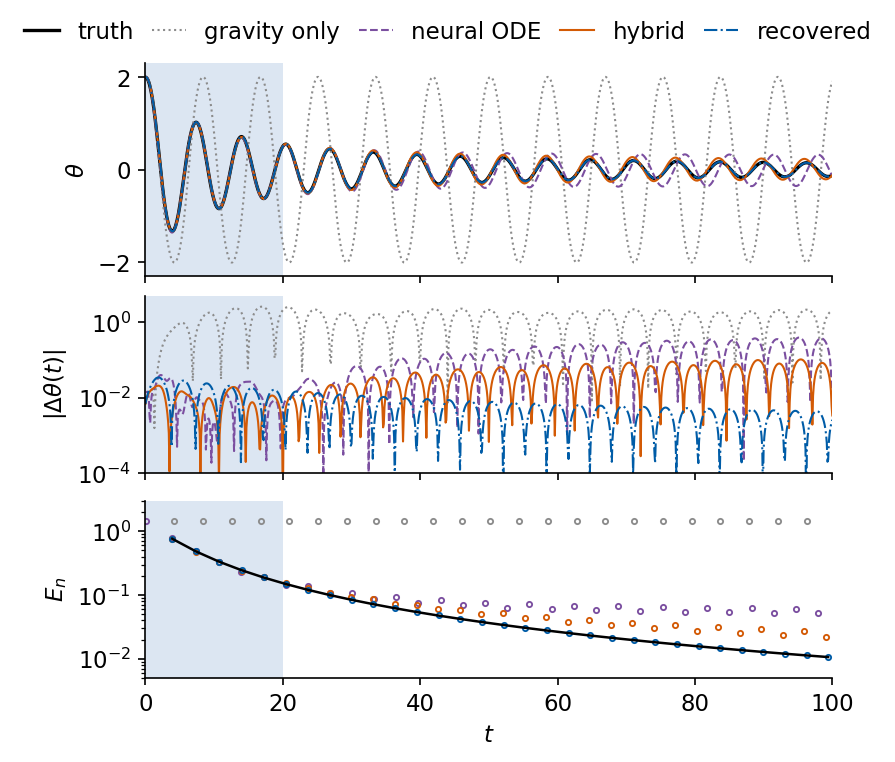

In [19]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(3, 1, figsize=(5.5, 5.0), layout="constrained", sharex=True,
                            gridspec_kw={"height_ratios": [1.2, 1, 1]})
    for ax in axs:
        ax.axvspan(0, T_TRAIN, color="#DCE6F2", lw=0, zorder=0)
    axs[0].plot(t_grid, true[LAW][:, 0], **STYLE["truth"], lw=1.6, label="truth")
    for name in MODEL_NAMES:
        axs[0].plot(t_grid, fc[name][:, 0], **STYLE[name], lw=1.0, label=name)
        axs[1].semilogy(t_grid, np.maximum(err[name], 1e-5), **STYLE[name], lw=1.0)
        tp, A = turning_points(t_grid, fc[name][:, 0], min_amp=0.02)
        axs[2].semilogy(tp, W0SQ * (1 - np.cos(A)), "o", color=STYLE[name]["color"], ms=2.5, mfc="none", mew=0.9)
    tp, A = turning_points(t_grid, true[LAW][:, 0], min_amp=0.02)
    axs[2].semilogy(tp, W0SQ * (1 - np.cos(A)), "-", color="k", lw=1.2)
    axs[0].set_ylabel(r"$\theta$"); axs[0].set_ylim(-2.3, 2.3)
    axs[1].set_ylabel(r"$|\Delta\theta(t)|$"); axs[1].set_ylim(1e-4, 5)
    axs[2].set_ylabel(r"$E_n$"); axs[2].set_ylim(5e-3, 3); axs[2].set_xlabel("$t$")
    axs[2].set_xlim(0, T_END)
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=5, handlelength=1.5,
               columnspacing=0.8)
    save(fig, "fig_lab043_forecast"); plt.show()

<hr/>
## 7. Other friction laws

A useful procedure must also recognise the other friction laws. We therefore repeat it for the viscous and the dry friction, with new noisy measurements of the same length and noise level, the same training budget and the same library, threshold and ridge penalty.

The library contains the smoothed sign function with the same width $\varepsilon$ as the simulation, which makes the dry case easier than it would be with measured data, where the width would also have to be scanned. We also test a second form of the hybrid model. Friction in a bearing or in air depends on how fast the bob moves and is independent of where it is, so we may build this into the model and let the network depend on the angular velocity alone,
$$\ddot\theta=-\omega_0^2\sin\theta+U_\theta(\dot\theta). \tag{14}$$
This network has one input and 1153 parameters. A single swing passes through every velocity between $-\dot\theta_{\max}$ and $\dot\theta_{\max}$ many times, so a function of $\dot\theta$ alone is constrained over that whole interval, whereas a function of two variables is constrained only on the thin spiral of measured states. For each law and each form of the network we tabulate the recovered friction, the coefficient of the true term and the forecast error of the recovered equation for $20<t\le100$.

In [20]:
def f_hybrid_v(params):
    # hybrid model with a friction network of the angular velocity alone
    return lambda s, t: jnp.array([s[1], -W0SQ * jnp.sin(s[0]) + mlp(params, s[1:2])[0]])
SIZES_V = [1, 32, 32, 1]
print("parameters of U_theta(thetadot):", n_params(init_mlp(jax.random.PRNGKey(0), SIZES_V)))
nums["n_params_Uv"] = n_params(init_mlp(jax.random.PRNGKey(0), SIZES_V))

VARIANTS = {"angle and velocity": (f_hybrid, SIZES_U, lambda p, S: mlp(p, S)[:, 0]),
            "velocity only": (f_hybrid_v, SIZES_V, lambda p, S: mlp(p, S[:, 1:2])[:, 0])}
table, learned = {}, {}
for law in LAWS:
    d_ = data if law == LAW else measure(law, np.random.default_rng(10 + LAWS.index(law)))
    for var, (f_maker, sizes, U_eval) in VARIANTS.items():
        if law == LAW and var == "angle and velocity":
            p_ = fits["hybrid"]["params"]
        else:
            t0 = time.time()
            p_, _, l_ = train(f_maker, init_mlp(jax.random.PRNGKey(0), sizes, last_scale=0.1), d_)
            print(f"{law:9s} {var:18s} trained in {time.time() - t0:.0f} s, loss {l_:.2e}")
        U_ = np.asarray(U_eval(p_, jnp.asarray(d_)))
        F_ = np.asarray(FRICTION[law](d_[:, 1], COEF[law]))
        x_ = sparse_fit(d_, U_)
        x0_ = stlsq(library(d_), U_, LAM_REL * np.sqrt(np.mean(U_ ** 2)), alpha=0.0)     # without the ridge penalty
        tr_ = np.asarray(rk4_solve(f_from_xi(x_), jnp.asarray(d_[0]), 0.0, N_END, DT))
        table[(law, var)] = dict(formula=formula(x_), coef=float(-x_[LIB_NAMES.index(LAW_TERM[law])]),
                                 n_terms=int((x_ != 0).sum()), formula_plain=formula(x0_),
                                 U_err=float(np.sqrt(np.mean((U_ - F_) ** 2) / np.mean(F_ ** 2))),
                                 rms_test=float(np.sqrt(np.mean((tr_[test, 0] - true[law][test, 0]) ** 2))))
        learned[(law, var)] = (d_, U_, p_)
print()
print(f"{'law':10s} {'network input':19s} {'err(U)':>7s} {'true':>6s} {'found':>8s} {'rms dtheta':>11s}   STLSQ result")
for (law, var), r in table.items():
    print(f"{law:10s} {var:19s} {r['U_err']:7.3f} {COEF[law]:6.3f} {r['coef']:8.4f} {r['rms_test']:11.4f}   {r['formula']}")
print()
for (law, var), r in table.items():
    print(f"without ridge, {law:10s} {var:19s}: {r['formula_plain']}")
nums["laws"] = {f"{law} | {var}": r for (law, var), r in table.items()}

parameters of U_theta(thetadot): 1153
viscous   angle and velocity trained in 110 s, loss 6.81e-04
viscous   velocity only      trained in 86 s, loss 7.17e-04
quadratic velocity only      trained in 73 s, loss 5.99e-04
dry       angle and velocity trained in 89 s, loss 8.06e-04
dry       velocity only      trained in 81 s, loss 8.94e-04

law        network input        err(U)   true    found  rms dtheta   STLSQ result
viscous    angle and velocity    0.173  0.100   0.1008      0.0117   -0.1008 \dot\theta
viscous    velocity only         0.090  0.100   0.1017      0.0145   -0.1017 \dot\theta
quadratic  angle and velocity    0.076  0.150   0.1497      0.0057   -0.1497 \dot\theta|\dot\theta|
quadratic  velocity only         0.035  0.150   0.1505      0.0046   -0.1505 \dot\theta|\dot\theta|
dry        angle and velocity    0.720  0.050   0.0488      0.0259   -0.0488 \tanh(\dot\theta/\varepsilon)
dry        velocity only         0.312  0.050   0.0489      0.0244   -0.0489 \tanh(\dot\theta/\

For all three laws and both forms of the network STLSQ selects a single term, the one that generated the data. The recovered coefficients for the network of both variables and for the velocity-only network are 0.1008 and 0.1017 for $\gamma=0.1$, 0.1497 and 0.1505 for $c=0.15$, and 0.0488 and 0.0489 for $\mu=0.05$, and the recovered equations forecast the swing for $20<t\le100$ with angle errors between 0.005 and 0.026. The velocity-only network approximates the true friction better, with err$(U)$ of 0.09, 0.035 and 0.31 against 0.17, 0.076 and 0.72 for the network of both variables. Dry friction is the hardest case for both networks. The smooth tanh units do not form the step of width $\varepsilon=0.05$ from these data, and the learned function oscillates around the two plateaus. The projection onto the library still selects $\tanh(\dot\theta/\varepsilon)$, since no other library function follows the oscillations. Without the ridge penalty the regression keeps four correlated velocity terms for dry friction with both networks, while for the other two laws it selects the same single term.

For each law we plot the friction learned by the velocity-only network on a grid of $\dot\theta$ inside the measured range, the true law, and the friction term recovered by STLSQ. The error measure is err$(U)={\rm rms}(U_\theta-F)/{\rm rms}(F)$ over the measured states.

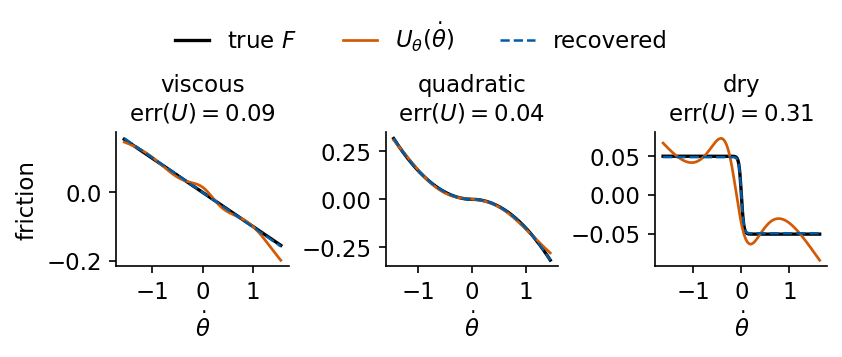

In [21]:
with mpl.rc_context(SLIDE_RC):
    fig, axs = plt.subplots(1, 3, figsize=(5.5, 2.3), layout="constrained")
    for ax, law in zip(axs, LAWS):
        d_, U_, p_ = learned[(law, "velocity only")]
        wm = np.abs(d_[:, 1]).max()
        wg = np.linspace(-wm, wm, 301)
        Ug = np.asarray(mlp(p_, jnp.asarray(wg)[:, None])[:, 0])
        x_ = sparse_fit(d_, U_)
        Sg = np.stack([np.zeros_like(wg), wg], 1)
        Fr = library(Sg)[:, 4:] @ x_[4:]                 # velocity terms of the recovered formula
        ax.plot(wg, FRICTION[law](wg, COEF[law]), color="k", lw=1.6, label="true $F$")
        ax.plot(wg, Ug, color=DSOrange, lw=1.3, label=r"$U_\theta(\dot\theta)$")
        ax.plot(wg, Fr, color=UJBlue, ls="--", lw=1.2, label="recovered")
        r = table[(law, "velocity only")]
        ax.set_title(law + "\n" + rf"err$(U)={r['U_err']:.2f}$"); ax.set_xlabel(r"$\dot\theta$")
    axs[0].set_ylabel("friction")
    fig.legend(*axs[0].get_legend_handles_labels(), loc="outside upper center", ncol=3, handlelength=1.5)
    save(fig, "fig_lab043_three_laws"); plt.show()

<hr/>
## Recovered friction and forecast accuracy

We modelled a pendulum whose friction law was hidden in one noisy swing of three periods. A pure neural ODE with 1218 parameters fits the measured swing, but once the swing leaves the region of the phase plane covered by the data its forecast degrades, with an angle error of 0.18 for $20<t\le100$. The hybrid model keeps the known gravitational term and lets a network of 1185 parameters represent the friction inside the equation of motion. Trained through the RK4 solver with a multiple-shooting loss, it learns a friction function within 7.6 per cent of the true law on the measured states and forecasts with an error of 0.048. Sequentially thresholded ridge regression on the network output selects a single term from a library of eight candidates, the quadratic air drag, with the coefficient 0.1497 for the true 0.15. The recovered equation forecasts with an error of 0.006 and reproduces the energy decay to $t=100$. The same procedure selects the correct term for viscous and for dry friction, and a network that depends on the angular velocity alone, a physical assumption about friction, learns the friction more accurately than a network of the whole state. Regressing the library directly on finite-difference derivatives of the noisy data selects no term at all, since differentiation amplifies the noise above the size of the friction, although a fit of the true term alone to the same derivatives gives $c=0.148$.

These results hold for this setting, a noise level of 0.02, one swing of three periods and a library that contains the true term. The threshold window in which the single correct term survives is narrow, less than a factor of two in $\lambda$, because the candidate velocity functions are strongly correlated on the data. When the true law is absent from the library, the regression returns the sparse combination of library terms that best approximates it in the measured range, and nothing then guarantees that it extrapolates better than the network.

## References

- C. Rackauckas, Y. Ma, J. Martensen, C. Warner, K. Zubov, R. Supekar, D. Skinner, A. Ramadhan, A. Edelman, *Universal Differential Equations for Scientific Machine Learning*, [arXiv:2001.04385](https://arxiv.org/abs/2001.04385)
- S. L. Brunton, J. L. Proctor, J. N. Kutz, *Discovering governing equations from data by sparse identification of nonlinear dynamical systems*, PNAS **113**, 3932 (2016), [doi:10.1073/pnas.1517384113](https://doi.org/10.1073/pnas.1517384113)
- R. T. Q. Chen, Y. Rubanova, J. Bettencourt, D. Duvenaud, *Neural Ordinary Differential Equations*, [arXiv:1806.07366](https://arxiv.org/abs/1806.07366)
- P. Kidger, *On Neural Differential Equations*, PhD thesis, University of Oxford (2021), [arXiv:2202.02435](https://arxiv.org/abs/2202.02435)
- Ch. Tsitouras, *Runge–Kutta pairs of order 5(4) satisfying only the first column simplifying assumption*, Comput. Math. Appl. **62**, 770 (2011), [doi:10.1016/j.camwa.2011.06.002](https://doi.org/10.1016/j.camwa.2011.06.002)
- D. P. Kingma, J. Ba, *Adam: a method for stochastic optimization*, [arXiv:1412.6980](https://arxiv.org/abs/1412.6980)

All numbers quoted in the text are collected in a JSON file and as LaTeX macros.

In [22]:
nums["runtime_s"] = round(time.time() - t_start, 1)
def to_py(o):
    if isinstance(o, dict): return {str(k): to_py(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)): return [to_py(v) for v in o]
    if isinstance(o, (np.floating, np.integer)): return o.item()
    return o
with open(f"{OUT}/numbers_lab043.json", "w") as fh:
    json.dump(to_py(nums), fh, indent=1)

# LaTeX macros \labfortythree... (letters only) for the numbers the slides use
MODTAG = {"gravity only": "Gravity", "neural ODE": "NeuralODE", "hybrid": "Hybrid", "recovered": "Recovered"}
LAWTAG = {"viscous": "Viscous", "quadratic": "Quadratic", "dry": "Dry"}
macros = {}
VARTAG = {"angle and velocity": "AngleVel", "velocity only": "VelOnly"}
for law in LAWS:
    macros[f"Coef{LAWTAG[law]}"] = f"{COEF[law]:g}"
    for var in VARIANTS:
        r = table[(law, var)]
        macros[f"Recovered{LAWTAG[law]}{VARTAG[var]}"] = f"{r['coef']:.4f}"
        macros[f"Terms{LAWTAG[law]}{VARTAG[var]}"] = str(r["n_terms"])
        macros[f"UErr{LAWTAG[law]}{VARTAG[var]}"] = f"{r['U_err']:.2f}"
        macros[f"RmsTestRecovered{LAWTAG[law]}{VARTAG[var]}"] = f"{r['rms_test']:.3f}"
    macros[f"DecaySlope{LAWTAG[law]}"] = f"{nums[f'decay_slope_{law}']:.3f}"
    macros[f"DecayPred{LAWTAG[law]}"] = f"{nums[f'decay_pred_{law}']:.3f}"
for m in MODEL_NAMES:
    macros[f"RmsTrain{MODTAG[m]}"] = f"{nums[f'rms_train_{m}']:.3f}"
    macros[f"RmsTest{MODTAG[m]}"] = f"{nums[f'rms_test_{m}']:.3f}"
    macros[f"EHundred{MODTAG[m]}"] = f"{nums[f'E100_{m}']:.4f}"
macros["EHundredTruth"] = f"{nums['E100_truth']:.4f}"
macros["CRecovered"] = f"{nums['c_recovered']:.4f}"
macros["CFiniteDiffSingle"] = f"{nums['c_fd_single']:.3f}"      # true column alone; STLSQ on raw derivatives selects no term
macros["TermsFiniteDiff"] = str(int(np.count_nonzero(xi_fd)))
macros["Sigma"] = f"{SIGMA:g}"
macros["NData"] = str(nums["n_data"])
macros["ParamsU"] = str(nums["n_params_U"]); macros["ParamsUv"] = str(nums["n_params_Uv"]); macros["ParamsN"] = str(nums["n_params_N"])
macros["LossHybrid"] = f"{nums['loss_hybrid']:.5f}"; macros["LossNeuralODE"] = f"{nums['loss_neural ODE']:.5f}"
macros["LossGravity"] = f"{nums['loss_gravity']:.4f}"
macros["URelError"] = f"{nums['U_rel_error_data']:.3f}"
def tex_sci(v):
    # 2.5e-06 -> 2.5\times10^{-6} (for use in math mode)
    m, e = f"{v:.1e}".split("e")
    return f"{m}\\times10^{{{int(e)}}}"
macros["GradDiffOne"] = tex_sci(nums["grad_rel_diff_sub1"]); macros["GradDiffFour"] = tex_sci(nums["grad_rel_diff_sub4"])
macros["LamSingleMin"] = f"{nums['lam_single_min']:.3f}"; macros["LamSingleMax"] = f"{nums['lam_single_max']:.2f}"
macros["Runtime"] = f"{nums['runtime_s'] / 60:.1f}"
bad = [k for k in macros if not k.isalpha()]
assert not bad, bad
with open(f"{OUT}/nb_numbers_lab043.tex", "w") as fh:
    for k, val in macros.items():
        fh.write(f"\\newcommand{{\\labfortythree{k}}}{{{val}}}\n")
print(f"{len(macros)} macros written; total runtime {nums['runtime_s'] / 60:.1f} min")

63 macros written; total runtime 10.8 min
